# CIPAT 2: Supply Chain Analytics Using Python

## Problem Statement
Analysis of supply chain data to understand sales performance,
delivery performance, customer segments, product categories,
and factors related to late deliveries.

## Dataset
DataCo Supply Chain Dataset

## Objectives
1. Perform data preprocessing and cleaning.
2. Analyze sales and profit performance.
3. Analyze delivery and shipping performance.
4. Apply statistical and probability techniques.
5. Perform hypothesis testing.
6. Visualize important supply chain patterns.
7. Build a machine learning model for late delivery risk prediction.

In [40]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn

print("Libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("SciPy version:", scipy.__version__)

Libraries imported successfully!
Pandas version: 2.2.3
NumPy version: 2.1.3
SciPy version: 1.16.3


In [41]:
from google.colab import files

uploaded = files.upload()

Saving DataCoSupplyChainDataset.csv to DataCoSupplyChainDataset (3).csv


In [42]:
# Load the dataset

df = pd.read_csv("DataCoSupplyChainDataset.csv", encoding="latin1")

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully!
Rows: 180519
Columns: 53


In [43]:
# Basic dataset inspection

print("Dataset Shape:", df.shape)

print("\nFirst 5 Records:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

Dataset Shape: (180519, 53)

First 5 Records:


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class



Column Names:
['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City', 'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id', 'Customer Lname', 'Customer Password', 'Customer Segment', 'Customer State', 'Customer Street', 'Customer Zipcode', 'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Customer Id', 'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status', 'Order Zipcode', 'Product Card Id', 'Product Category Id', 'Product Description', 'Product Image', 'Product Name', 'Product Price', 'Product Status', 'shipping

In [44]:
# Check missing values

missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values[missing_values > 0])

Missing Values in Each Column:
Customer Lname              8
Customer Zipcode            3
Order Zipcode          155679
Product Description    180519
dtype: int64


In [45]:
# Calculate missing value percentage

missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_table = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Percentage': missing_percentage
})

print("Missing Value Analysis:")
display(missing_table[missing_table['Missing Values'] > 0])

Missing Value Analysis:


,Missing Values,Percentage
Customer Lname,8,0.004432
Customer Zipcode,3,0.001662
Order Zipcode,155679,86.239676
Product Description,180519,100.000000


In [46]:
# Check the data type and sample values of missing-value columns

columns_to_check = [
    'Customer Lname',
    'Customer Zipcode',
    'Order Zipcode',
    'Product Description'
]

for col in columns_to_check:
    print(f"\n--- {col} ---")
    print("Data Type:", df[col].dtype)
    print("Sample Values:")
    print(df[col].dropna().head().tolist())


--- Customer Lname ---
Data Type: object
Sample Values:
['Holloway', 'Luna', 'Maldonado', 'Tate', 'Hendricks']

--- Customer Zipcode ---
Data Type: float64
Sample Values:
[725.0, 725.0, 95125.0, 90027.0, 725.0]

--- Order Zipcode ---
Data Type: float64
Sample Values:
[99301.0, 90049.0, 94110.0, 66212.0, 77041.0]

--- Product Description ---
Data Type: float64
Sample Values:
[]


In [47]:
# Handle missing values

# Fill small number of missing values
df['Customer Lname'] = df['Customer Lname'].fillna('Unknown')
df['Customer Zipcode'] = df['Customer Zipcode'].fillna(
    df['Customer Zipcode'].median()
)

# Remove columns with very high missing values
df.drop(columns=['Order Zipcode', 'Product Description'], inplace=True)

print("Missing values handled successfully!")

Missing values handled successfully!


In [48]:
# Verify missing values after cleaning

remaining_missing = df.isnull().sum()

print(remaining_missing[remaining_missing > 0])

Series([], dtype: int64)


In [49]:
# Check duplicate records

duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [50]:
# Check data types

print("Data Types of All Columns:")
print(df.dtypes)

Data Types of All Columns:
Type                              object
Days for shipping (real)           int64
Days for shipment (scheduled)      int64
Benefit per order                float64
Sales per customer               float64
Delivery Status                   object
Late_delivery_risk                 int64
Category Id                        int64
Category Name                     object
Customer City                     object
Customer Country                  object
Customer Email                    object
Customer Fname                    object
Customer Id                        int64
Customer Lname                    object
Customer Password                 object
Customer Segment                  object
Customer State                    object
Customer Street                   object
Customer Zipcode                 float64
Department Id                      int64
Department Name                   object
Latitude                         float64
Longitude                     

In [51]:
# Data Structures used in Supply Chain Analytics

# 1. List - store selected columns
selected_columns = [
    'Sales',
    'Order Profit Per Order',
    'Shipping Mode',
    'Market'
]

print("List:")
print(selected_columns)


# 2. Tuple - store fixed KPI names
kpi_names = (
    'Total Sales',
    'Total Profit',
    'Total Orders'
)

print("\nTuple:")
print(kpi_names)


# 3. Dictionary - store basic dataset information
dataset_info = {
    'Rows': df.shape[0],
    'Columns': df.shape[1],
    'Topic': 'Supply Chain Analytics'
}

print("\nDictionary:")
print(dataset_info)


# 4. Set - find unique shipping modes
shipping_modes = set(df['Shipping Mode'].dropna())

print("\nSet of Shipping Modes:")
print(shipping_modes)

List:
['Sales', 'Order Profit Per Order', 'Shipping Mode', 'Market']

Tuple:
('Total Sales', 'Total Profit', 'Total Orders')

Dictionary:
{'Rows': 180519, 'Columns': 51, 'Topic': 'Supply Chain Analytics'}

Set of Shipping Modes:
{'Same Day', 'Second Class', 'First Class', 'Standard Class'}


In [52]:
# Using Python Libraries in Supply Chain Analytics

# Pandas - Data analysis
print("Pandas:")
print("Average Sales =", df['Sales'].mean())

# NumPy - Numerical calculation
print("\nNumPy:")
print("Maximum Sales =", np.max(df['Sales']))
print("Minimum Sales =", np.min(df['Sales']))

# SciPy - Statistical calculation
from scipy import stats

print("\nSciPy:")
print("Sales Mean =", stats.tmean(df['Sales']))

# Matplotlib - Visualization
print("\nMatplotlib:")
print("Matplotlib is used for creating charts and graphs.")

# Seaborn - Statistical visualization
print("\nSeaborn:")
print("Seaborn is used for statistical data visualization.")

# Scikit-learn - Machine Learning
print("\nScikit-learn:")
print("Scikit-learn will be used later for Machine Learning.")

Pandas:
Average Sales = 203.77209608617287

NumPy:
Maximum Sales = 1999.98999
Minimum Sales = 9.989999771

SciPy:
Sales Mean = 203.77209608617287

Matplotlib:
Matplotlib is used for creating charts and graphs.

Seaborn:
Seaborn is used for statistical data visualization.

Scikit-learn:
Scikit-learn will be used later for Machine Learning.


In [53]:
# Create a custom Python module

%%writefile supply_chain_utils.py

def calculate_average_sales(df):
    return df['Sales'].mean()

def calculate_total_profit(df):
    return df['Order Profit Per Order'].sum()

def calculate_late_delivery_percentage(df):
    return df['Late_delivery_risk'].mean() * 100

Overwriting supply_chain_utils.py


In [54]:
# Import and use our custom module

import supply_chain_utils

print("Average Sales:", supply_chain_utils.calculate_average_sales(df))

print("Total Profit:", supply_chain_utils.calculate_total_profit(df))

print(
    "Late Delivery Percentage:",
    supply_chain_utils.calculate_late_delivery_percentage(df)
)

Average Sales: 203.77209608617287
Total Profit: 3966902.9740503575
Late Delivery Percentage: 54.82913155955883


In [55]:
# Exception Handling for File Operations

try:
    test_df = pd.read_csv("wrong_file_name.csv")
    print("File loaded successfully!")

except FileNotFoundError:
    print("Error: File not found. Please check the file name.")

except Exception as e:
    print("An unexpected error occurred:", e)

Error: File not found. Please check the file name.


In [56]:
# File Handling - Save cleaned dataset

cleaned_file = "Cleaned_Supply_Chain_Dataset.csv"

df.to_csv(cleaned_file, index=False)

print("Cleaned dataset saved successfully!")
print("File name:", cleaned_file)

Cleaned dataset saved successfully!
File name: Cleaned_Supply_Chain_Dataset.csv


In [57]:
# CRUD Operations Demonstration

crud_df = df[['Order Id', 'Sales', 'Shipping Mode']].head(5).copy()

print("Initial Records:")
display(crud_df)

Initial Records:


,Order Id,Sales,Shipping Mode
0,77202,327.75,Standard Class
1,75939,327.75,Standard Class
2,75938,327.75,Standard Class
3,75937,327.75,Standard Class
4,75936,327.75,Standard Class


In [58]:
# CREATE: Add a new supply chain record

new_record = pd.DataFrame({
    'Order Id': [999999],
    'Sales': [500.00],
    'Shipping Mode': ['Standard Class']
})

crud_df = pd.concat([crud_df, new_record], ignore_index=True)

print("After CREATE:")
display(crud_df)

After CREATE:


,Order Id,Sales,Shipping Mode
0,77202,327.75,Standard Class
1,75939,327.75,Standard Class
2,75938,327.75,Standard Class
3,75937,327.75,Standard Class
4,75936,327.75,Standard Class
5,999999,500.00,Standard Class


In [59]:
# READ: Display the records

print("After READ:")
display(crud_df)

After READ:


,Order Id,Sales,Shipping Mode
0,77202,327.75,Standard Class
1,75939,327.75,Standard Class
2,75938,327.75,Standard Class
3,75937,327.75,Standard Class
4,75936,327.75,Standard Class
5,999999,500.00,Standard Class


In [60]:
# UPDATE: Modify an existing record

crud_df.loc[crud_df['Order Id'] == 999999, 'Sales'] = 600.00

print("After UPDATE:")
display(crud_df)

After UPDATE:


,Order Id,Sales,Shipping Mode
0,77202,327.75,Standard Class
1,75939,327.75,Standard Class
2,75938,327.75,Standard Class
3,75937,327.75,Standard Class
4,75936,327.75,Standard Class
5,999999,600.00,Standard Class


In [61]:
# DELETE: Remove an existing record

crud_df = crud_df[crud_df['Order Id'] != 999999]

print("After DELETE:")
display(crud_df)

After DELETE:


,Order Id,Sales,Shipping Mode
0,77202,327.75,Standard Class
1,75939,327.75,Standard Class
2,75938,327.75,Standard Class
3,75937,327.75,Standard Class
4,75936,327.75,Standard Class


In [62]:
# NumPy Implementation

sales_array = np.array(df['Sales'])

print("Sales as NumPy Array:")
print(sales_array[:10])

print("\nNumPy Calculations:")
print("Mean Sales:", np.mean(sales_array))
print("Maximum Sales:", np.max(sales_array))
print("Minimum Sales:", np.min(sales_array))
print("Standard Deviation:", np.std(sales_array))

Sales as NumPy Array:
[327.75 327.75 327.75 327.75 327.75 327.75 327.75 327.75 327.75 327.75]

NumPy Calculations:
Mean Sales: 203.77209608617287
Maximum Sales: 1999.98999
Minimum Sales: 9.989999771
Standard Deviation: 132.2727111303442


In [63]:
# SciPy Implementation - Paired Hypothesis Test

from scipy.stats import ttest_rel

test_data = df[
    ['Days for shipping (real)',
     'Days for shipment (scheduled)']
].dropna()

statistic, p_value = ttest_rel(
    test_data['Days for shipping (real)'],
    test_data['Days for shipment (scheduled)']
)

print("Paired t-test Results")
print("T-statistic:", statistic)
print("P-value:", p_value)

Paired t-test Results
T-statistic: 161.2361121465159
P-value: 0.0


In [64]:
# Pandas Implementation - Supply Chain Analysis

# Filter records with high sales
high_sales = df[df['Sales'] > 500]

print("Orders with Sales greater than 500:")
display(high_sales[['Order Id', 'Sales', 'Shipping Mode']].head(10))


# Grouping and aggregation
sales_by_shipping = df.groupby('Shipping Mode')['Sales'].sum()

print("\nTotal Sales by Shipping Mode:")
print(sales_by_shipping)

Orders with Sales greater than 500:


,Order Id,Sales,Shipping Mode
152,70734,1500.000000,Second Class
155,70769,1500.000000,Second Class
160,70534,1500.000000,Second Class
172,70544,1500.000000,Second Class
174,68879,999.989990,Second Class
1353,70617,1500.000000,Standard Class
1370,70746,1500.000000,Standard Class
1375,70744,1500.000000,Standard Class
1594,70795,1500.000000,Second Class
2325,71986,532.580017,Standard Class



Total Sales by Shipping Mode:
Shipping Mode
First Class       5.674370e+06
Same Day          1.942529e+06
Second Class      7.145445e+06
Standard Class    2.202239e+07
Name: Sales, dtype: float64


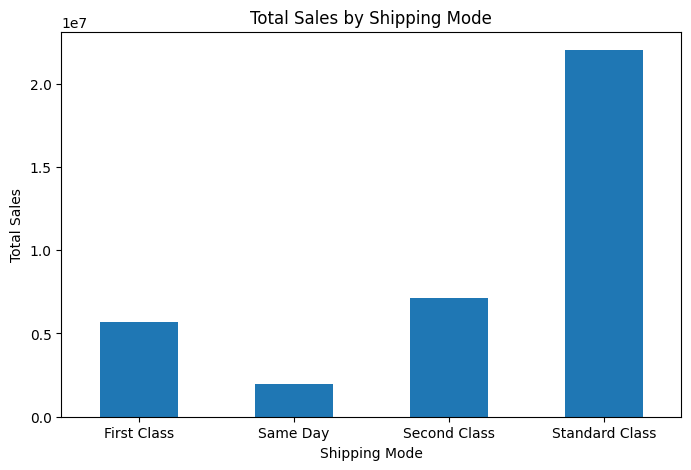

In [65]:
# Data Visualization - Sales by Shipping Mode

sales_by_shipping = df.groupby('Shipping Mode')['Sales'].sum()

plt.figure(figsize=(8,5))
sales_by_shipping.plot(kind='bar')

plt.title('Total Sales by Shipping Mode')
plt.xlabel('Shipping Mode')
plt.ylabel('Total Sales')

plt.xticks(rotation=0)
plt.show()

In [66]:
# Statistical Analysis of Top 5 Order Profit Per Order Records

profit = df['Order Profit Per Order'].head(5)

print("Top 5 Order Profit Per Order Records")
print("-------------------------------------")
print(profit)

print("\nStatistical Analysis of Top 5 Order Profit Per Order")
print("-----------------------------------------------------")
print("Mean:", profit.mean())
print("Median:", profit.median())
print("Mode:", profit.mode().tolist())
print("Standard Deviation:", profit.std())
print("Variance:", profit.var())
print("Minimum:", profit.min())
print("Maximum:", profit.max())
print("Skewness:", profit.skew())
print("Kurtosis:", profit.kurt())

Top 5 Order Profit Per Order Records
-------------------------------------
0     91.250000
1   -249.089996
2   -247.779999
3     22.860001
4    134.210007
Name: Order Profit Per Order, dtype: float64

Statistical Analysis of Top 5 Order Profit Per Order
-----------------------------------------------------
Mean: -49.709997558
Median: 22.86000061
Mode: [-249.0899963, -247.7799988, 22.86000061, 91.25, 134.2100067]
Standard Deviation: 185.70595224863112
Variance: 34486.70070057086
Minimum: -249.0899963
Maximum: 134.2100067
Skewness: -0.40935860452485984
Kurtosis: -3.0748027457090075


In [67]:
print("Order Profit Per Order")
print("----------------------")
print(df['Order Profit Per Order'])

Order Profit Per Order
----------------------
0          91.250000
1        -249.089996
2        -247.779999
3          22.860001
4         134.210007
             ...    
180514     40.000000
180515   -613.770019
180516    141.110001
180517    186.229996
180518    168.949997
Name: Order Profit Per Order, Length: 180519, dtype: float64


In [68]:
# Probability of Late Delivery Risk

total_orders = len(df)

late_orders = df['Late_delivery_risk'].sum()

probability_late = late_orders / total_orders

print("Total Orders:", total_orders)
print("Orders with Late Delivery Risk:", late_orders)
print("Probability of Late Delivery Risk:", probability_late)
print("Probability (%):", probability_late * 100)

Total Orders: 180519
Orders with Late Delivery Risk: 98977
Probability of Late Delivery Risk: 0.5482913155955883
Probability (%): 54.82913155955883


In [69]:
# Sampling and Inference

# Take a random sample of 1000 records
sample_df = df.sample(n=1000, random_state=42)

# Calculate population and sample mean
population_mean = df['Sales'].mean()
sample_mean = sample_df['Sales'].mean()

print("Population Size:", len(df))
print("Sample Size:", len(sample_df))
print("Population Mean Sales:", population_mean)
print("Sample Mean Sales:", sample_mean)

Population Size: 180519
Sample Size: 1000
Population Mean Sales: 203.77209608617287
Sample Mean Sales: 208.694964250081


In [70]:
# Web Scraping Libraries

import requests
from bs4 import BeautifulSoup
import pandas as pd

print("Web scraping libraries imported successfully!")

Web scraping libraries imported successfully!


In [71]:
# Fetch webpage

url = "https://books.toscrape.com/"

response = requests.get(url)

print("Status Code:", response.status_code)

if response.status_code == 200:
    print("Webpage fetched successfully!")
else:
    print("Failed to fetch webpage.")

Status Code: 200
Webpage fetched successfully!


In [72]:
# Parse HTML using BeautifulSoup

soup = BeautifulSoup(response.text, "html.parser")

print("HTML parsed successfully!")

HTML parsed successfully!


In [73]:
# Extract book information

books = []

for book in soup.find_all("article", class_="product_pod"):

    title = book.h3.a["title"]
    price = book.find("p", class_="price_color").text
    availability = book.find("p", class_="instock availability").text.strip()

    books.append({
        "Product": title,
        "Price": price,
        "Availability": availability
    })

scraped_df = pd.DataFrame(books)

display(scraped_df)

,Product,Price,Availability
0,A Light in the Attic,Â£51.77,In stock
1,Tipping the Velvet,Â£53.74,In stock
2,Soumission,Â£50.10,In stock
3,Sharp Objects,Â£47.82,In stock
4,Sapiens: A Brief History of Humankind,Â£54.23,In stock
5,The Requiem Red,Â£22.65,In stock
6,The Dirty Little Secrets of Getting Your Dream...,Â£33.34,In stock
7,The Coming Woman: A Novel Based on the Life of...,Â£17.93,In stock
8,The Boys in the Boat: Nine Americans and Their...,Â£22.60,In stock
9,The Black Maria,Â£52.15,In stock


In [74]:
# Basic analysis of scraped data

print("Number of products scraped:", len(scraped_df))

print("\nScraped Dataset:")
display(scraped_df.head())

print("\nDataset Shape:", scraped_df.shape)

print("\nColumn Names:")
print(scraped_df.columns.tolist())

Number of products scraped: 20

Scraped Dataset:


,Product,Price,Availability
0,A Light in the Attic,Â£51.77,In stock
1,Tipping the Velvet,Â£53.74,In stock
2,Soumission,Â£50.10,In stock
3,Sharp Objects,Â£47.82,In stock
4,Sapiens: A Brief History of Humankind,Â£54.23,In stock



Dataset Shape: (20, 3)

Column Names:
['Product', 'Price', 'Availability']


In [75]:
# Save scraped data

scraped_df.to_csv("Web_Scraped_Supply_Chain_Data.csv", index=False)

print("Web scraped data saved successfully!")

Web scraped data saved successfully!


In [76]:
# Machine Learning Libraries

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Machine Learning libraries imported successfully!")

Machine Learning libraries imported successfully!


In [77]:
# Select features for Late Delivery Risk Prediction

features = [
    'Days for shipment (scheduled)',
    'Sales',
    'Order Item Quantity',
    'Product Price'
]

target = 'Late_delivery_risk'

X = df[features]
y = df[target]

print("Features:")
print(features)

print("\nTarget:", target)

print("\nFeature Shape:", X.shape)
print("Target Shape:", y.shape)

Features:
['Days for shipment (scheduled)', 'Sales', 'Order Item Quantity', 'Product Price']

Target: Late_delivery_risk

Feature Shape: (180519, 4)
Target Shape: (180519,)


In [78]:
# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 144415
Testing records: 36104


In [79]:
# Feature Scaling

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")

Feature scaling completed successfully!


In [80]:
# Build Logistic Regression Model

model = LogisticRegression(random_state=42)

model.fit(X_train_scaled, y_train)

print("Machine Learning model trained successfully!")

Machine Learning model trained successfully!


In [81]:
# Make predictions

y_pred = model.predict(X_test_scaled)

print("Predictions generated successfully!")

print("\nFirst 20 Predictions:")
print(y_pred[:20])

Predictions generated successfully!

First 20 Predictions:
[0 0 0 1 1 0 1 0 1 1 0 1 0 1 0 0 0 0 1 0]


In [82]:
# Calculate Model Accuracy

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)
print("Model Accuracy (%):", accuracy * 100)

Model Accuracy: 0.6918900952803013
Model Accuracy (%): 69.18900952803013


In [83]:
# Classification Report

print("Classification Report:")
print(classification_report(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

           0       0.62      0.82      0.71     16308
           1       0.80      0.59      0.68     19796

    accuracy                           0.69     36104
   macro avg       0.71      0.70      0.69     36104
weighted avg       0.72      0.69      0.69     36104



Confusion Matrix:
[[13340  2968]
 [ 8156 11640]]


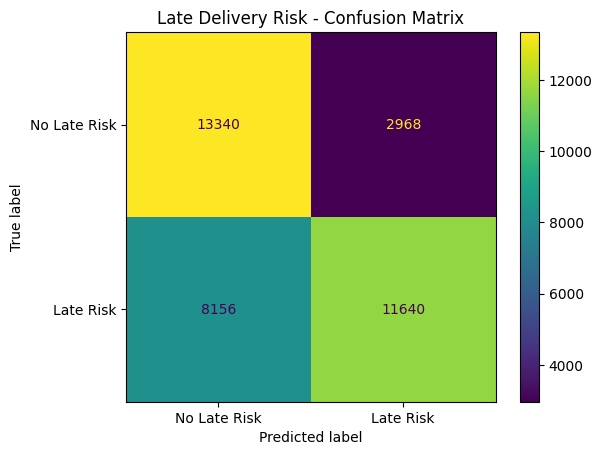

In [84]:
# Confusion Matrix

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No Late Risk', 'Late Risk']
)

disp.plot()
plt.title("Late Delivery Risk - Confusion Matrix")
plt.show()

In [85]:
# Example: Predict Late Delivery Risk for a new order

new_order = pd.DataFrame({
    'Days for shipment (scheduled)': [4],
    'Sales': [250],
    'Order Item Quantity': [2],
    'Product Price': [125]
})

new_order_scaled = scaler.transform(new_order)

prediction = model.predict(new_order_scaled)[0]

if prediction == 1:
    print("Prediction: HIGH RISK OF LATE DELIVERY")
else:
    print("Prediction: LOW RISK OF LATE DELIVERY")

Prediction: LOW RISK OF LATE DELIVERY
